# Experiment 6: Machine Learning Forecasting Using Regression and Tree-Based Models

**Course:** Time Series Analysis and Forecasting  
**Course Code:** CS3216  
**Experiment Date:** 05-11-2026  
**Student Name:** Chetana S  
**USN:** 1RUA24CSE0107  

---

## 1. Aim
To develop and evaluate machine learning forecasting models using a regression model and tree-based models on time-series data, by converting the time series into a supervised learning dataset using lag and calendar-related features.

## 2. Learning Outcomes
- Understand how a time series can be converted into a supervised learning problem.
- Create lag-based and rolling statistical features for forecasting.
- Train a regression model and tree-based models for predicting future values.
- Evaluate and compare models using MAE, RMSE and MAPE.
- Understand why chronological train-test splitting is required for time-series forecasting.

## 3. Software and Requirements
Python 3.x, Jupyter Notebook, NumPy, pandas, Matplotlib and scikit-learn. XGBoost is optional.

## 4. Background / Theory
Most general machine-learning algorithms do not automatically understand the order of time-series observations. Therefore, the series is transformed into a supervised-learning dataset. Previous observations become input features and the current observation becomes the target:

\[
X_t = [Y_{t-1}, Y_{t-2}, Y_{t-3}, \ldots], \qquad Target = Y_t
\]

- **Linear Regression:** Learns a linear numerical relationship between the input features and target.
- **Decision Tree Regressor:** Splits the feature space into regions using feature-based conditions and predicts a value for each region.
- **Random Forest Regressor:** Averages predictions from multiple decision trees trained using different samples and feature subsets, reducing the instability of a single tree.
- **XGBoost (optional):** Builds trees sequentially, where each new tree attempts to reduce errors made by the existing ensemble.

## 5. Dataset
The supplied illustrative monthly demand dataset contains 36 observations (three years). The first 80% of the feature-ready observations are used for training and the final 20% for testing. The observations are **not shuffled**.

In [1]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Display settings
pd.set_option("display.float_format", lambda x: f"{x:.2f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully.")

Libraries imported successfully.


## 6. Create the Monthly Demand Dataset
The dataset below is copied from the experiment sheet. The time index runs from 1 to 36.

In [2]:
demand = [
    120, 128, 135, 132, 145, 153, 160, 158, 170, 178, 185, 195,
    190, 202, 210, 207, 220, 230, 238, 235, 250, 260, 268, 280,
    275, 288, 298, 295, 310, 322, 330, 328, 342, 355, 365, 378
]

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

df = pd.DataFrame({"demand": demand})
df["time"] = np.arange(1, len(df) + 1)
df["month"] = [months[i % 12] for i in range(len(df))]

df = df[["time", "month", "demand"]]
display(df.head(12))
print(f"Total observations: {len(df)}")

,time,month,demand
0,1,Jan,120
1,2,Feb,128
2,3,Mar,135
3,4,Apr,132
4,5,May,145
5,6,Jun,153
6,7,Jul,160
7,8,Aug,158
8,9,Sep,170
9,10,Oct,178


Total observations: 36


## 7. Convert the Time Series into a Supervised-Learning Dataset
Create lag features for the previous 1, 2 and 3 observations. The rolling mean is shifted by one period **before** applying the 3-period rolling window so that the current target is not included (avoids target leakage).

In [3]:
# Keep a working copy with the demand and time columns
model_df = pd.DataFrame({
    "demand": demand,
    "time": np.arange(1, len(demand) + 1)
})

# Generate lag features
for lag in [1, 2, 3]:
    model_df[f"lag_{lag}"] = model_df["demand"].shift(lag)

# Shift first, then calculate the rolling mean
model_df["rolling_mean_3"] = (
    model_df["demand"].shift(1).rolling(window=3).mean()
)

print("Dataset before removing missing feature rows:")
display(model_df.head(6))

model_df = model_df.dropna().reset_index(drop=True)

features = ["time", "lag_1", "lag_2", "lag_3", "rolling_mean_3"]
X = model_df[features]
y = model_df["demand"]

print(f"Rows after feature generation and dropna: {len(model_df)}")
display(model_df.head())

Dataset before removing missing feature rows:


,demand,time,lag_1,lag_2,lag_3,rolling_mean_3
0,120,1,NaN,NaN,NaN,NaN
1,128,2,120.00,NaN,NaN,NaN
2,135,3,128.00,120.00,NaN,NaN
3,132,4,135.00,128.00,120.00,127.67
4,145,5,132.00,135.00,128.00,131.67
5,153,6,145.00,132.00,135.00,137.33


Rows after feature generation and dropna: 33


,demand,time,lag_1,lag_2,lag_3,rolling_mean_3
0,132,4,135.00,128.00,120.00,127.67
1,145,5,132.00,135.00,128.00,131.67
2,153,6,145.00,132.00,135.00,137.33
3,160,7,153.00,145.00,132.00,143.33
4,158,8,160.00,153.00,145.00,152.67


## 8. Chronological 80:20 Train-Test Split
The first 80% of feature-ready rows are used for training and the last 20% for testing. No random shuffling is performed because forecasting must preserve time order.

In [4]:
split = int(len(model_df) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training time indices:", model_df.loc[:split-1, "time"].min(),
      "to", model_df.loc[:split-1, "time"].max())
print("Testing time indices:", model_df.loc[split:, "time"].min(),
      "to", model_df.loc[split:, "time"].max())

assert model_df.loc[:split-1, "time"].max() < model_df.loc[split:, "time"].min()
print("Chronological split verified: training data precedes testing data.")

Training observations: 26
Testing observations: 7
Training time indices: 4 to 29
Testing time indices: 30 to 36
Chronological split verified: training data precedes testing data.


## 9. Define, Train and Evaluate the Models
The required models are Linear Regression, Decision Tree Regressor and Random Forest Regressor. Evaluation metrics:

- **MAE:** Mean Absolute Error; lower is better.
- **RMSE:** Root Mean Squared Error; lower is better and larger errors receive more weight.
- **MAPE:** Mean Absolute Percentage Error; lower is better.

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=3, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=4, random_state=42
    )
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mape = np.mean(np.abs((y_test.to_numpy() - y_pred) /
                          y_test.to_numpy())) * 100

    results[name] = [mae, rmse, mape]
    predictions[name] = y_pred

results_df = pd.DataFrame(
    results, index=["MAE", "RMSE", "MAPE (%)"]
).T

print("Model comparison:")
display(results_df.round(2))

Model comparison:


,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75


## 10. Actual vs Predicted Demand Plot
The plot compares actual demand with the predictions from all three models for the final 20% test period.

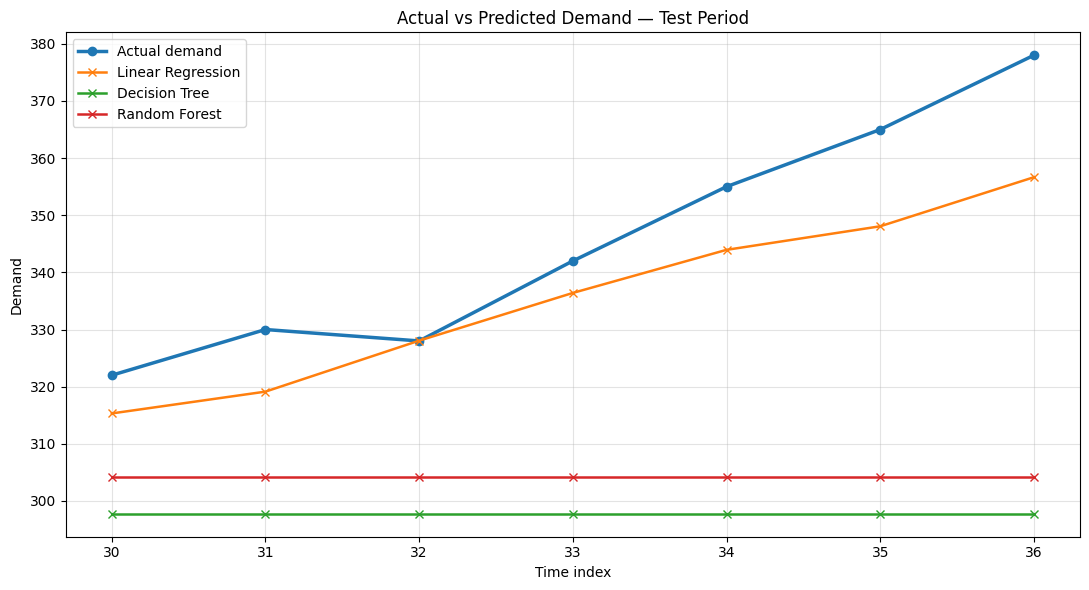

In [6]:
plt.figure(figsize=(11, 6))
plt.plot(model_df.loc[split:, "time"], y_test.values,
         marker="o", linewidth=2.5, label="Actual demand")

for name, y_pred in predictions.items():
    plt.plot(model_df.loc[split:, "time"], y_pred,
             marker="x", linewidth=1.8, label=name)

plt.xlabel("Time index")
plt.ylabel("Demand")
plt.title("Actual vs Predicted Demand — Test Period")
plt.xticks(model_df.loc[split:, "time"])
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

## 11. Optional: XGBoost Model
This section is optional as mentioned in the experiment sheet. If XGBoost is not installed, install it using `pip install xgboost` in a notebook cell or terminal, then rerun this section.

In [7]:
try:
    from xgboost import XGBRegressor

    xgb_model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42
    )

    xgb_model.fit(X_train, y_train)
    xgb_pred = xgb_model.predict(X_test)

    xgb_mae = mean_absolute_error(y_test, xgb_pred)
    xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
    xgb_mape = np.mean(np.abs(
        (y_test.to_numpy() - xgb_pred) / y_test.to_numpy()
    )) * 100

    results_df.loc["XGBoost"] = [xgb_mae, xgb_rmse, xgb_mape]
    predictions["XGBoost"] = xgb_pred

    print("XGBoost metrics:")
    print(f"MAE: {xgb_mae:.2f}")
    print(f"RMSE: {xgb_rmse:.2f}")
    print(f"MAPE (%): {xgb_mape:.2f}")

except ImportError:
    print("XGBoost is not installed; optional section skipped.")

display(results_df.round(2))

XGBoost metrics:
MAE: 42.11
RMSE: 46.37
MAPE (%): 11.91


,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75
XGBoost,42.11,46.37,11.91


## 12. Observations and Analysis

**10. Which model produced the lowest MAE?**  
Linear Regression produced the lowest MAE (10.36), meaning its average absolute prediction error was the smallest among the three required models.

**11. Which model produced the lowest RMSE? Was it the same model as in the previous question?**  
Linear Regression produced the lowest RMSE (12.30). Yes, it was also the model with the lowest MAE. RMSE penalizes larger errors more strongly than MAE.

**12. Which model followed the upward trend most closely in the test period?**  
Linear Regression followed the upward trend most closely. Its predictions increased across the test period and broadly tracked the increase in actual demand from 322 to 378. The tree-based models produced nearly constant predictions over the test observations.

**13. Did the Decision Tree perform differently from the Random Forest? Give a possible reason.**  
Yes. The Decision Tree had MAE 47.96 and RMSE 51.74, while the Random Forest had MAE 41.57 and RMSE 45.88. Random Forest performed better because it averages predictions from many trees, generally reducing the variance and instability of a single tree. Both tree-based models were less effective at extrapolating the continuing upward trend.

**14. Why is random shuffling inappropriate for this forecasting experiment?**  
Random shuffling mixes earlier and later observations between training and testing sets. The model may then learn from information that would not have been available at the forecast time, causing data leakage and an unrealistically optimistic evaluation. A chronological split preserves the real forecasting order.

**15. What could happen if the current target value were accidentally included in a rolling feature?**  
The feature would contain information from the value the model is supposed to predict. This is target leakage. It can make evaluation results look unusually accurate, but the feature would not be available for a genuine forecast, making the measured performance misleading.

## 13. Precautions
- Never shuffle time-series observations before splitting into training and testing sets.
- Use only information available before or at the forecast origin to construct features.
- Do not include the target observation in its own lag or rolling features.
- For a real forecasting task, use rolling/expanding-window validation rather than relying only on one holdout split.
- The sample data is illustrative; model performance on it should not be interpreted as evidence of real-world forecasting quality.

## 14. Conclusion
The experiment converted the monthly demand time series into a supervised-learning dataset using a time index, three lag features and a shifted 3-period rolling mean. A chronological 80:20 split was used to prevent future observations from entering the training data. Among the three required models, Linear Regression performed best on the test set, achieving the lowest MAE (10.36), RMSE (12.30) and MAPE (2.92%). Random Forest performed better than the single Decision Tree, but both tree-based models produced nearly flat predictions and did not capture the upward trend as effectively. Therefore, Linear Regression was the best-performing model for this illustrative dataset and test period. These results apply only to the supplied sample data and should not be generalized to real-world forecasting without further validation.

---

**Student Name:** Chetana S  
**USN:** 1RUA24CSE0107  
**Experiment Date:** 05-11-2026